# SentinelAI — Malicious URL Detection

## 1. Project Overview

### About the Project

The internet has a huge number of URLs, and not all of them are safe. Some URLs are created to steal personal information, redirect users to harmful websites, or take advantage of compromised websites.

In this project, I am working on **SentinelAI**, a machine learning-based system that analyzes URLs and predicts whether they belong to different security-related categories.

The main idea is simple: instead of checking every URL manually, we can use patterns in the URL itself to help identify potentially suspicious URLs.

### What I Want to Achieve

Through this project, I aim to:

- Understand the patterns present in malicious and legitimate URLs.
- Explore and clean the available URL dataset.
- Extract useful features from URLs.
- Build machine learning models for URL classification.
- Compare different models and evaluate their performance.
- Understand which URL characteristics are important for the predictions.
- Save the best-performing model for further use.
- Eventually connect the model with an API and a simple user interface.

### Dataset

The dataset used in this project contains URLs along with their corresponding categories.

The main categories include:

- **Benign** — URLs that are considered legitimate.
- **Phishing** — URLs commonly associated with attempts to trick users into revealing sensitive information.
- **Defacement** — URLs related to websites that have been modified or compromised.

The dataset will first be explored to understand its size, structure, class distribution, missing values, and duplicate records.

### Project Approach

The project will be developed step by step:

1. Load and understand the dataset.
2. Check the quality of the data.
3. Perform exploratory data analysis.
4. Study URL patterns and characteristics.
5. Create useful URL-based features.
6. Prepare the data for machine learning.
7. Train and compare classification models.
8. Evaluate the models using suitable metrics.
9. Analyze the important features behind the predictions.
10. Save the final model for future integration.

### Tools Used

- **Python 3.10**
- **Pandas & NumPy** for data processing
- **Matplotlib & Seaborn** for visualization
- **Scikit-learn** for machine learning
- **Joblib** for saving the trained model
- **Jupyter Notebook / VS Code** for development
- **Streamlit & FastAPI** for the planned application layer

### Project Goal

The goal is not only to build a model with good accuracy, but also to understand **why certain URLs are more likely to be classified as malicious**.

This will make the project more useful as a cybersecurity-focused machine learning system and provide a better foundation for deploying the model in a real application.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
# Load the dataset

DATA_PATH = Path("../data/raw/malicious_phish.csv")

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
df.head()

Dataset loaded successfully!
Shape: (651191, 2)


,url,type
0,br-icloud.com.br,phishing
1,mp3raid.com/music/krizz_kaliko.html,benign
2,bopsecrets.org/rexroth/cr/1.htm,benign
3,http://www.garage-pirenne.be/index.php?option=...,defacement
4,http://adventure-nicaragua.net/index.php?optio...,defacement


## 2. Dataset Overview and Initial Inspection

### Objective

The objective of this section is to perform an initial assessment of the dataset before proceeding with exploratory data analysis and feature engineering.

The dataset contains URLs labeled according to their security-related category. Understanding the dataset structure, class distribution, missing values, and duplicate records is essential for identifying data-quality issues and potential class imbalance.

### Key Checks

The following aspects will be examined:

- **Dataset dimensions:** Number of observations and features.
- **Missing values:** Identification of incomplete records.
- **Duplicate records:** Detection of repeated observations.
- **Target distribution:** Distribution of URL categories.
- **Class proportions:** Percentage contribution of each URL category.

These checks provide a foundation for subsequent data cleaning, exploratory analysis, feature engineering, and machine-learning model development.

In [4]:
# Basic Dataset Inspection

print("Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nURL Type Distribution:")
print(df["type"].value_counts())

print("\nURL Type Percentage:")
print((df["type"].value_counts(normalize=True) * 100).round(2))

Dataset Shape: (651191, 2)

Missing Values:
url     0
type    0
dtype: int64

Duplicate Rows: 10066

URL Type Distribution:
type
benign        428103
defacement     96457
phishing       94111
malware        32520
Name: count, dtype: int64

URL Type Percentage:
type
benign        65.74
defacement    14.81
phishing      14.45
malware        4.99
Name: proportion, dtype: float64


## 3. Data Cleaning

The dataset does not contain missing values, but it contains duplicate URL records. These duplicates can affect the analysis and may cause data leakage during model training.

We will remove duplicate rows before continuing with the analysis.

In [5]:
# Remove duplicate records

df = df.drop_duplicates().reset_index(drop=True)

print("Shape after removing duplicates:", df.shape)
print("Remaining duplicates:", df.duplicated().sum())

Shape after removing duplicates: (641125, 2)
Remaining duplicates: 0


In [6]:
# Check class distribution

class_counts = df["type"].value_counts()

print(class_counts)

type
benign        428080
defacement     95308
phishing       94092
malware        23645
Name: count, dtype: int64


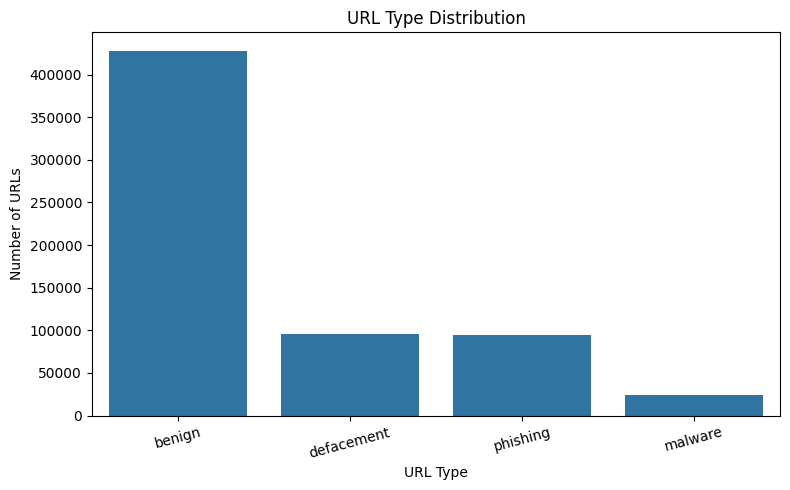

In [7]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="type", order=class_counts.index)

plt.title("URL Type Distribution")
plt.xlabel("URL Type")
plt.ylabel("Number of URLs")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()